# Information

# 0. Setup
load required libs
specify paths

In [2]:
import qiime2 as q2
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score

In [6]:
data_dir = "../../data"
featuretable_dir = "../../output/02_taxonomicclassification"

# 1. Data Import

In [4]:
meta = pd.read_csv(f"{data_dir}/metadata.tsv", sep="\t", index_col="sample-id")
meta.head()
meta.columns

Index(['collection_date', 'country', 'instrument', 'sample_number',
       'delivery_mode', 'host_sex', 'diet_milk', 'city', 'latitude',
       'longitude', 'urca_code', 'urca_description', 'host_id', 'host_age',
       'seq_depth', 'age_months'],
      dtype='object')

In [7]:
table = q2.Artifact.load(f"{featuretable_dir}/feature-table.qza").view(pd.DataFrame)

# 2. MAZ (microbiota-by-age Z-score)

In [8]:
idx = table.index.intersection(meta.index)
X = table.loc[idx]                                  # same input as your baseline (counts)
y = meta.loc[idx, "host_age"].astype(float)
groups = meta.loc[idx, "host_id"]

# 1) out-of-fold predictions for all samples (infant-grouped)
rf = RandomForestRegressor(n_estimators=500, random_state=22, n_jobs=-1)
pred = cross_val_predict(rf, X, y, groups=groups, cv=GroupKFold(n_splits=5))
print("grouped-CV R2:", r2_score(y, pred))


# 2) residuals and MAZ (z-score within each age, all samples as reference)
df = meta.loc[idx, ["host_id", "host_age", "delivery_mode", "diet_milk", "host_sex"]].copy()
df["pred"] = pred
df["resid"] = df["pred"] - df["host_age"]
g = df.groupby("host_age")["resid"]
df["MAZ"] = (df["resid"] - g.transform("mean")) / g.transform("std")

# 4) mixed model, infant as random effect
d2 = df.dropna(subset=["MAZ", "delivery_mode", "diet_milk", "host_sex"])
m = smf.mixedlm("MAZ ~ C(delivery_mode) + C(diet_milk) + C(host_sex) + C(host_age)",
                d2, groups=d2["host_id"]).fit()
print(m.summary())

grouped-CV R2: 0.7856564376506132
                Mixed Linear Model Regression Results
Model:                 MixedLM      Dependent Variable:      MAZ      
No. Observations:      143          Method:                  REML     
No. Groups:            38           Scale:                   0.8317   
Min. group size:       2            Log-Likelihood:          -198.9830
Max. group size:       5            Converged:               Yes      
Mean group size:       3.8                                            
----------------------------------------------------------------------
                            Coef.  Std.Err.   z    P>|z| [0.025 0.975]
----------------------------------------------------------------------
Intercept                    0.343    0.345  0.995 0.320 -0.333  1.018
C(delivery_mode)[T.vaginal] -0.284    0.196 -1.447 0.148 -0.669  0.101
C(diet_milk)[T.mixed]        0.113    0.207  0.545 0.586 -0.293  0.519
C(host_sex)[T.male]          0.147    0.190  0.775 0.439 -0.

# 3. Visualization of MAZ

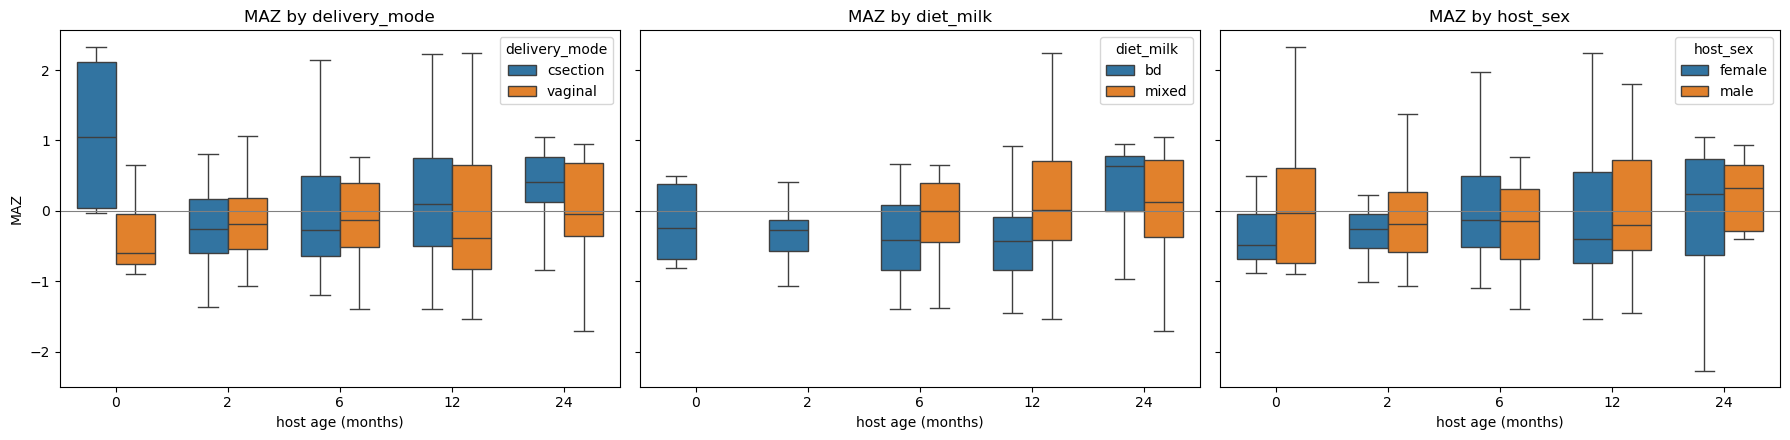

In [13]:
cols = ["delivery_mode", "diet_milk", "host_sex"]
ages = sorted(df["host_age"].unique())
kind = "box"            # "box" or "violin"
add_lines = False       # True = overlay thin per-infant trajectories

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, col in zip(axes, cols):
    order = sorted(df[col].dropna().unique())
    common = dict(data=df, x="host_age", y="MAZ", hue=col, hue_order=order, ax=ax)

    if kind == "box":
        sns.boxplot(**common, order=ages, showfliers=False, width=0.7)
    else:
        sns.violinplot(**common, order=ages, cut=0, inner="quartile", density_norm="width")


    if add_lines:
        pos = {a: i for i, a in enumerate(ages)}          # map age -> categorical position
        for _, g in df.sort_values("host_age").groupby("host_id"):
            ax.plot(g["host_age"].map(pos), g["MAZ"], color="grey", lw=0.6, alpha=0.3, zorder=0)

    ax.axhline(0, color="grey", lw=0.8)
    ax.set(xlabel="host age (months)", ylabel="MAZ", title=f"MAZ by {col}")
plt.tight_layout()
plt.show()